In [26]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Cihaz:", device)

Cihaz: cpu


In [27]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_set = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_set, val_set = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

print("Train:", len(train_set), "| Validation:", len(val_set), "| Test:", len(test_set))

BATCH_SIZE = 64
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

Train: 50000 | Validation: 10000 | Test: 10000


In [28]:
class MLP(nn.Module):
    def __init__(self, hidden1=256, hidden2=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 10)
        )

    def forward(self, x):
        return self.net(x)

model = MLP().to(device)
print(model)
print("Parametre sayısı:", sum(p.numel() for p in model.parameters()))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parametre sayısı: 235146


In [29]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    if training:
        model.train()
    else:
        model.eval()

    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


def train_model(model, epochs=10, lr=0.001):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, loss_fn, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, loss_fn)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

        print(f"Epoch {epoch:2d}/{epochs} | "
              f"train loss {tr_loss:.4f}, acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f}, acc {va_acc:.4f}")

    elapsed = time.time() - start
    print(f"Eğitim süresi: {elapsed:.1f} saniye")
    return history, elapsed

In [ ]:
EPOCHS = 10
LR = 0.001
history, train_time = train_model(model, epochs=EPOCHS, lr=LR)

Epoch  1/10 | train loss 0.2493, acc 0.9248 | val loss 0.1344, acc 0.9592


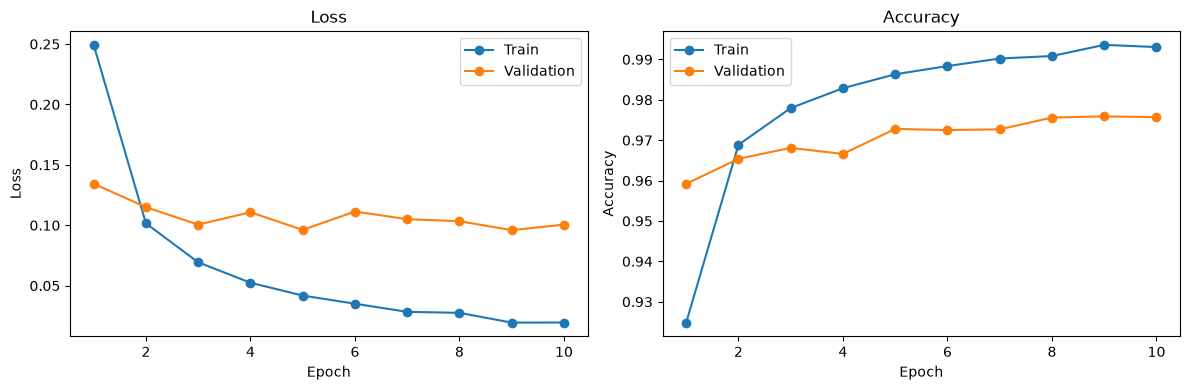

In [ ]:
epochs_range = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs_range, history["train_loss"], marker="o", label="Train")
ax1.plot(epochs_range, history["val_loss"], marker="o", label="Validation")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(epochs_range, history["train_acc"], marker="o", label="Train")
ax2.plot(epochs_range, history["val_acc"], marker="o", label="Validation")
ax2.set_title("Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()

plt.tight_layout()
plt.savefig("loss_accuracy.png", dpi=120)
plt.show()

In [ ]:
loss_fn = nn.CrossEntropyLoss()
test_loss, test_acc = run_epoch(model, test_loader, loss_fn)

print("===== Deney 1 Sonuçları =====")
print(f"Training loss      : {history['train_loss'][-1]:.4f}")
print(f"Validation loss    : {history['val_loss'][-1]:.4f}")
print(f"Training accuracy  : {history['train_acc'][-1]:.4f}")
print(f"Validation accuracy: {history['val_acc'][-1]:.4f}")
print(f"Test accuracy      : {test_acc:.4f}")
print(f"Eğitim süresi      : {train_time:.1f} saniye")

===== Deney 1 Sonuçları =====
Training loss      : 0.0195
Validation loss    : 0.1005
Training accuracy  : 0.9931
Validation accuracy: 0.9757
Test accuracy      : 0.9789
Eğitim süresi      : 106.9 saniye


In [ ]:
from PIL import Image, ImageOps, ImageFilter

def otsu_threshold(arr):
    hist, _ = np.histogram(arr, bins=256, range=(0, 256))
    total = arr.size
    sum_all = np.dot(np.arange(256), hist)
    sum_b, w_b, best_t, best_var = 0.0, 0, 0, 0.0
    for t in range(256):
        w_b += hist[t]
        if w_b == 0:
            continue
        w_f = total - w_b
        if w_f == 0:
            break
        sum_b += t * hist[t]
        m_b = sum_b / w_b
        m_f = (sum_all - sum_b) / w_f
        var = w_b * w_f * (m_b - m_f) ** 2
        if var > best_var:
            best_var, best_t = var, t
    return best_t

def load_ink_image(path, max_width=1200):
    img = ImageOps.exif_transpose(Image.open(path)).convert("L")
    if img.width > max_width:
        img = img.resize((max_width, int(img.height * max_width / img.width)))
    small = img.resize((max(1, img.width // 8), max(1, img.height // 8)))
    background = small.filter(ImageFilter.MaxFilter(5)).filter(ImageFilter.GaussianBlur(3)).resize(img.size)
    arr = np.array(background, dtype=np.float32) - np.array(img, dtype=np.float32)
    arr = np.clip(arr, 0, None)
    arr = arr / arr.max() * 255.0
    t = otsu_threshold(arr)
    arr[arr < t] = 0
    return arr

def split_digits(arr, min_ink_ratio=0.05):
    mask = arr > 0
    h, w = mask.shape
    labels = np.zeros((h, w), dtype=np.int32)
    comps = []
    for y0, x0 in zip(*np.nonzero(mask)):
        if labels[y0, x0]:
            continue
        label = len(comps) + 1
        labels[y0, x0] = label
        stack, pixels = [(y0, x0)], []
        while stack:
            y, x = stack.pop()
            pixels.append((y, x))
            for dy in (-1, 0, 1):
                for dx in (-1, 0, 1):
                    ny, nx = y + dy, x + dx
                    if 0 <= ny < h and 0 <= nx < w and mask[ny, nx] and not labels[ny, nx]:
                        labels[ny, nx] = label
                        stack.append((ny, nx))
        ys, xs = zip(*pixels)
        comps.append([min(xs), max(xs), min(ys), max(ys), len(pixels), [label]])
    max_size = max(c[4] for c in comps)
    comps = [c for c in comps if c[4] >= min_ink_ratio * max_size]
    comps.sort(key=lambda c: c[0])
    merged = []
    for c in comps:
        if merged:
            p = merged[-1]
            overlap = min(p[1], c[1]) - max(p[0], c[0])
            if overlap > 0.5 * min(p[1] - p[0], c[1] - c[0]):
                p[0], p[1] = min(p[0], c[0]), max(p[1], c[1])
                p[2], p[3] = min(p[2], c[2]), max(p[3], c[3])
                p[5] += c[5]
                continue
        merged.append(c)
    digits = []
    for x1, x2, y1, y2, _, labs in merged:
        piece = np.where(np.isin(labels, labs), arr, 0)[y1:y2 + 1, x1:x2 + 1]
        digits.append(piece)
    return digits

def stroke_width(digit):
    runs = []
    for row in (digit > 0):
        count = 0
        for v in row:
            if v:
                count += 1
            elif count:
                runs.append(count)
                count = 0
        if count:
            runs.append(count)
    return float(np.median(runs))

def to_mnist(digit):
    h, w = digit.shape
    grow = int(round(0.12 * max(h, w) - stroke_width(digit)))
    pad = max(grow, 0) + 2
    digit = np.pad(digit, pad)
    img = Image.fromarray(np.clip(digit, 0, 255).astype(np.uint8))
    if grow >= 2:
        size = grow + 1 if grow % 2 == 0 else grow + 2
        img = img.filter(ImageFilter.MaxFilter(size))
    arr = np.array(img, dtype=np.float32)
    ys, xs = np.where(arr > 0)
    arr = arr[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = arr.shape
    scale = 20.0 / max(h, w)
    new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
    small = Image.fromarray(arr.astype(np.uint8)).resize((new_w, new_h), Image.LANCZOS)
    small = np.array(small, dtype=np.float32)
    small = small / small.max() * 255.0
    yy, xx = np.indices(small.shape)
    cy = (yy * small).sum() / small.sum()
    cx = (xx * small).sum() / small.sum()
    top = min(max(int(round(14 - cy)), 0), 28 - new_h)
    left = min(max(int(round(14 - cx)), 0), 28 - new_w)
    canvas = np.zeros((28, 28), dtype=np.float32)
    canvas[top:top + new_h, left:left + new_w] = small
    return canvas.astype(np.uint8)

In [ ]:
import os

STUDENT_NO = "24120205039"
IMG_PATH = "ogrenci_no/ogrenci_no.jpg"

digits = split_digits(load_ink_image(IMG_PATH))
print("Bulunan rakam sayısı:", len(digits), "| Beklenen:", len(STUDENT_NO))
mnist_like = [to_mnist(d) for d in digits]

model.eval()
batch = torch.stack([transform(Image.fromarray(m)) for m in mnist_like]).to(device)
with torch.no_grad():
    probs = torch.softmax(model(batch), dim=1)
conf, preds = probs.max(dim=1)
preds = preds.cpu().tolist()
conf = conf.cpu().tolist()

predicted_no = "".join(str(p) for p in preds)
correct = sum(p == t for p, t in zip(predicted_no, STUDENT_NO))
print("Gerçek numara:", STUDENT_NO)
print("Tahmin       :", predicted_no)
print(f"Doğru rakam  : {correct}/{len(STUDENT_NO)} ({correct / len(STUDENT_NO):.2%})")

os.makedirs("ogrenci_no/islenmis", exist_ok=True)
n = len(mnist_like)
fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.2))
for i, (ax, m) in enumerate(zip(np.atleast_1d(axes), mnist_like)):
    true = STUDENT_NO[i] if i < len(STUDENT_NO) else "?"
    ax.imshow(m, cmap="gray")
    ax.set_title(f"Tahmin: {preds[i]} ({conf[i]:.0%})\nGerçek: {true}",
                 color="green" if str(preds[i]) == true else "red", fontsize=8)
    ax.axis("off")
    Image.fromarray(m).save(f"ogrenci_no/islenmis/rakam_{i + 1}.png")
plt.tight_layout()
plt.savefig("ogrenci_no/tahminler.png", dpi=120)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'ogrenci_no/ogrenci_no.jpg'